### 👥 Group Members Information

| Member | Student Name | Registration / Student ID |
| :--- | :--- | :--- |
| **Student 1** | | |
| **Student 2** | | |
| **Student 3** | | |

**Date:** ____________________

---

# Lecture 4 · Guided practical: sampling, splitting and label quality

**Machine Learning for Earth Observation · Year 3**

You will reproduce, on the real Kigali Sentinel-2 scene (3 September 2026), the experiments shown in Lecture 4:

| Step | What you do | Learning objectives | Time |
|---|---|---|---|
| 1 | Draw random, stratified and systematic samples | representative sampling (LO3) | 10 min |
| 2 | How often does random sampling miss a rare class? | sampling, imbalance (LO3, LO6) | 5 min |
| 3 | Measure spatial dependence with a correlogram | spatial dependence (LO7) | 5 min |
| 4 | Random vs grouped vs spatial-block cross-validation | partitioning, leakage (LO4, LO5, LO7, LO8) | 10 min |


**Data** (folder `ml4eo/data/`, opened with rasterio):
* the September Sentinel-2 image: 2380 × 1702 pixels of 20 m in UTM zone 36S (EPSG:32736), with its Scene Classification Layer (SCL);
* `kigali_training_table.csv`: the ML table already used in Lecture 3 practical.

⚠️ The class labels were derived from the image itself (Lecture 3). Absolute accuracies are therefore **optimistic**; we use them to compare **relative** effects.



## 0. Set-up

Only numpy, pandas, matplotlib and scikit-learn are needed, plus rasterio for reading the images.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, recall_score

import rasterio

In [2]:
import os
def find_data_dir():
    for candidate in ["../data", "../../data", "data", "ML4EO/data"]:
        if os.path.exists(candidate) and os.path.isdir(candidate):
            return candidate
    return "../data"

DATA = find_data_dir()                   # dynamically locate the data folder

def load_band(date, band):
    # Open one Sentinel-2 band of one date: reflectance 0-1, NaN where there is no data (value 0)
    path = f"{DATA}/{date}-00_00_{date}-23_59_Sentinel-2_L2A_{band}_(Raw).tiff"
    with rasterio.open(path) as src:
        a = src.read(1)
    a[a == 0] = np.nan
    return a


In [3]:
SCL_COLOURS = {0: (0, 0, 0), 1: (255, 0, 0), 2: (47, 47, 47), 3: (100, 50, 0), 4: (0, 160, 0), 5: (255, 230, 90),
               6: (0, 0, 255), 7: (128, 128, 128), 8: (192, 192, 192), 9: (255, 255, 255), 10: (100, 200, 255), 11: (255, 150, 255)}

def read_scl(date):
    # The scene classification is stored as a coloured picture: turn each colour back into its class code
    path = f"{DATA}/{date}-00_00_{date}-23_59_Sentinel-2_L2A_Scene_classification_map_.tiff"
    with rasterio.open(path) as src:
        rgb = np.round(src.read() * 255)             # 3 layers of colour values 0-255
    codes = np.zeros(rgb.shape[1:], dtype=np.uint8)   # 0 = no data
    for code_, (r, g_, b) in SCL_COLOURS.items():
        codes[(rgb[0] == r) & (rgb[1] == g_) & (rgb[2] == b)] = code_
    return codes

In [4]:
BANDS = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B11", "B12"]
 
s = {b: load_band("2026-09-03", b) for b in ["B02", "B03", "B04", "B08"]}    # September reflectance
scl = read_scl("2026-09-03")
ndvi = (s["B08"] - s["B04"]) / (s["B08"] + s["B04"])

In [5]:
stretch = lambda a: np.clip((a - np.nanpercentile(a, 2)) / (np.nanpercentile(a, 98) - np.nanpercentile(a, 2)), 0, 1)
rgb = np.nan_to_num(np.dstack([stretch(s["B04"]), stretch(s["B03"]), stretch(s["B02"])]), nan=1.0)
with rasterio.open(f"{DATA}/2026-09-03-00_00_2026-09-03-23_59_Sentinel-2_L2A_B04_(Raw).tiff") as src:
    ULX, ULY = src.bounds.left, src.bounds.top    # upper-left corner (m)
    MX, MY = src.res                              # metres per pixel (UTM coordinates are in metres)
    H, W, CRS = src.height, src.width, src.crs
extent = [ULX / 1000, (ULX + W * MX) / 1000, (ULY - H * MY) / 1000, ULY / 1000]   # [left, right, bottom, top] in km
print(f"grid {H} x {W} pixels, pixel {MX:.2f} x {MY:.2f} m, {CRS}")

grid 1702 x 2380 pixels, pixel 19.98 x 19.96 m, EPSG:32736


In [6]:
table = pd.read_csv(f"{DATA}/kigali_training_table.csv")
FEATURES = BANDS + ["NDVI", "MNDWI", "NDBI"]
print(table.shape); print(pd.crosstab(table["class"], table["source"]))

(1395, 25)
source             point  polygon
class                            
bare soil             25      200
built-up              42      300
dense vegetation      40      300
sparse vegetation     40      225
water                 23      200


In [7]:
STRATA = {4: "vegetation", 5: "not vegetated", 6: "water"}        # SCL codes used as strata
S_COL = {"vegetation": "#2E6B3F", "not vegetated": "#E0A526", "water": "#2A7FA8"}
rng = np.random.default_rng(42)

## Step 1 · Sampling designs  *(LO3)*

We use three SCL classes as **strata**: vegetation (4), not vegetated (5) and water (6). What share of the grid does each cover?

In [8]:
for code_, name in STRATA.items():
    print(f"{name:14s} {100 * (scl == code_).mean():6.2f}% of pixels")

vegetation      20.01% of pixels
not vegetated   76.24% of pixels
water            2.35% of pixels


In [9]:
N = 300

def simple_random(n):
    return rng.integers(0, H, n), rng.integers(0, W, n)

def stratified_random(n_per_stratum):
    rows, cols = [], []
    for code_ in STRATA:
        r, c = np.nonzero(scl == code_)                  # all pixels of this stratum
        pick = rng.choice(len(r), n_per_stratum, replace=False)
        rows += list(r[pick]); cols += list(c[pick])
    return np.array(rows), np.array(cols)

def systematic(n_rows, n_cols):
    r0, c0 = rng.integers(0, H // n_rows), rng.integers(0, W // n_cols)   # random start
    rr, cc = np.meshgrid(np.arange(r0, H, H // n_rows)[:n_rows], np.arange(c0, W, W // n_cols)[:n_cols], indexing="ij")
    return rr.ravel(), cc.ravel()

designs = {"Simple random": simple_random(N), "Stratified random": stratified_random(100), "Systematic 15 x 20": systematic(15, 20)}

def to_xy(r, c):                           # pixel row/col -> UTM easting/northing of the pixel centre (km)
    return (ULX + (c + 0.5) * MX) / 1000, (ULY - (r + 0.5) * MY) / 1000

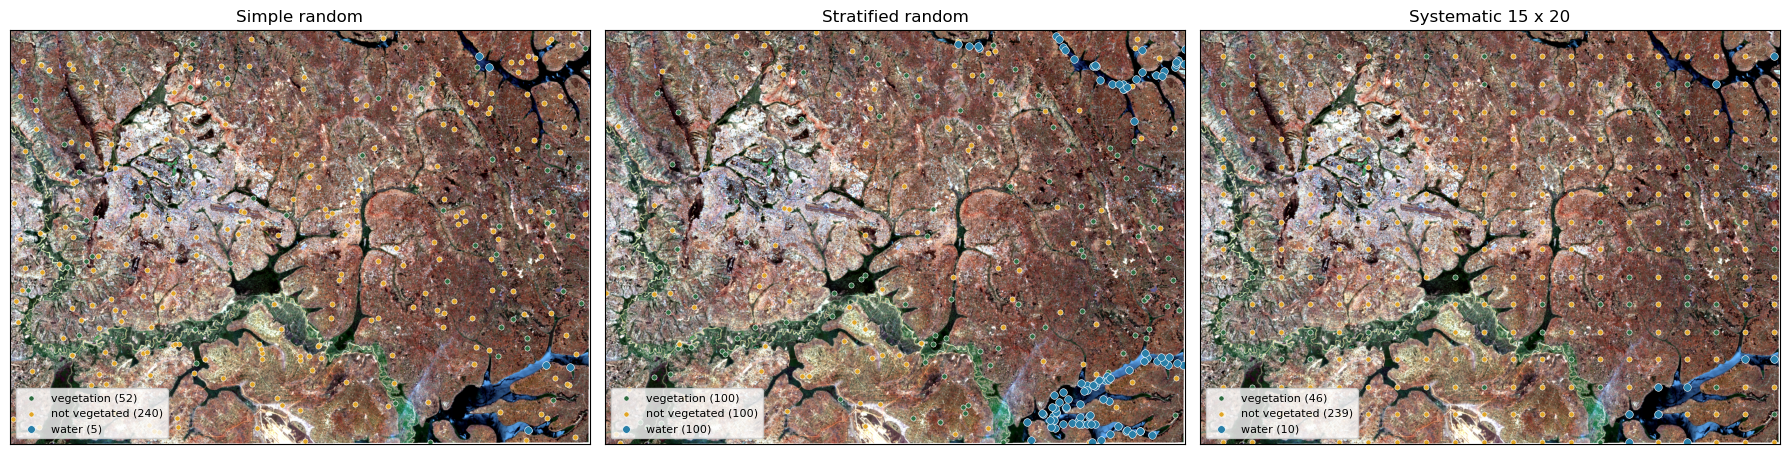

,Simple random,Stratified random,Systematic 15 x 20
not vegetated,240,100,239
other,3,0,5
vegetation,52,100,46
water,5,100,10


In [10]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.6))
counts = {}
for ax, (name, (r, c)) in zip(axs, designs.items()):
    xk, yk = to_xy(r, c)
    ax.imshow(rgb, extent=extent)
    lab = pd.Series(scl[r, c]).map(STRATA).fillna("other").values
    counts[name] = pd.Series(lab).value_counts()
    for k, col in S_COL.items():
        m = lab == k
        ax.scatter(xk[m], yk[m], s=14 if k != "water" else 30, color=col, edgecolor="white", lw=0.4, label=f"{k} ({m.sum()})")
    ax.set_title(name); ax.legend(loc="lower left", fontsize=8); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
pd.DataFrame(counts).fillna(0).astype(int)

**Question 1.** (a) How many water points did each design produce? (b) If you used the stratified sample to estimate the overall accuracy of a map, why could you not simply count the share of correct points?

*Your answer:*

- **(a) Water point counts:**
  - **Simple random:** Produced **5** water points (out of 300 total points).
  - **Stratified random:** Produced **100** water points (equal allocation of 100 per stratum).
  - **Systematic (15 × 20):** Produced **10** water points (out of 300 total points).

- **(b) Reason raw sample accuracy cannot be used for stratified sample:**
  Because the stratified design samples an equal number of points (100) per stratum, water constitutes 33.3% of the sample, even though it covers only **2.35%** of the true Kigali landscape (while non-vegetated land covers 76.24%). Simply computing the unweighted proportion of correct points across all 300 samples would over-represent water accuracy by roughly 14× and severely under-represent non-vegetated land. To obtain an unbiased estimate of overall map accuracy, the accuracy of each stratum must be weighted by its true population area proportion (area-weighted stratified estimation, following Olofsson et al., 2014).

## Step 2 · How often does simple random sampling miss a rare class?  *(LO3, LO6)*

In [11]:
water_counts = np.array([(scl[simple_random(N)] == 6).sum() for _ in range(1000)])
print(f"mean water points per sample: {water_counts.mean():.2f}")

mean water points per sample: 6.90


In [12]:
# TODO: percentage of the 1,000 samples that contain no water at all
pct_none = 100 * (water_counts == 0).mean()


samples with NO water:        0.0%
samples with fewer than 5:    17.9%


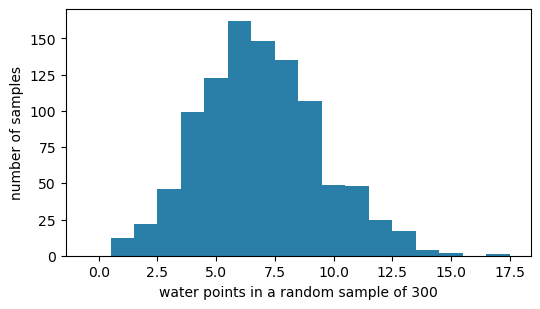

In [13]:
print(f"samples with NO water:        {pct_none:.1f}%")
print(f"samples with fewer than 5:    {100 * (water_counts < 5).mean():.1f}%")
plt.figure(figsize=(6, 3.2)); plt.hist(water_counts, bins=np.arange(-0.5, water_counts.max() + 1.5), color="#2A7FA8")
plt.xlabel("water points in a random sample of 300"); plt.ylabel("number of samples"); plt.show()

**Question 2.** What does this imply for training a water classifier, and for assessing the accuracy of its water class, with a simple random sample of 300?

*Your answer:*

- **Implications for training:** With an average of only ~7 water pixels in a random sample of 300 (and 18% of samples containing fewer than 5 pixels), a classifier receives too few training instances to learn spectral variability in water bodies (e.g., variations in depth, turbidity, and surface glint), typically capturing only 1 or 2 large lakes.
- **Implications for validation:** Estimating class-specific accuracy from only 5–10 test points yields wide, unreliable confidence intervals (sampling error of roughly ±20 percentage points). For rare classes (<5% of a scene), stratified or targeted sampling is necessary to ensure adequate sample sizes for both model learning and rigorous accuracy assessment.

## Step 3 · Spatial dependence: an NDVI correlogram  *(LO7)*

For each distance class we draw random pairs of pixels about that far apart and compute the correlation of their NDVI values.

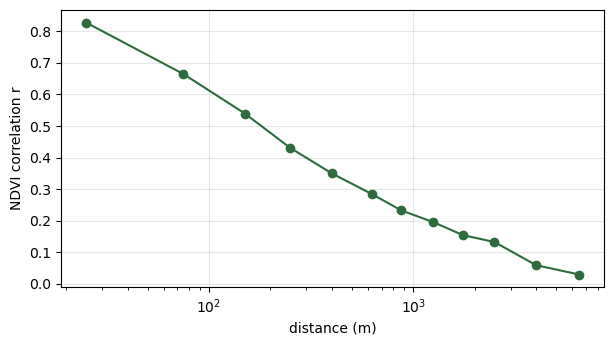

,from_m,to_m,mid_m,r
0,0,50,25.0,0.828
1,50,100,75.0,0.664
2,100,200,150.0,0.539
3,200,300,250.0,0.430
4,300,500,400.0,0.350
5,500,750,625.0,0.285
6,750,1000,875.0,0.232
7,1000,1500,1250.0,0.196
8,1500,2000,1750.0,0.154
9,2000,3000,2500.0,0.132


In [14]:
def correlogram(img, bins_m, n_pairs=30000):
    rows = []
    for lo, hi in zip(bins_m[:-1], bins_m[1:]):
        r1, c1 = rng.integers(0, H, n_pairs), rng.integers(0, W, n_pairs)
        d = rng.uniform(max(lo, 1), hi, n_pairs); theta = rng.uniform(0, 2 * np.pi, n_pairs)
        # Second pixel of each pair, d metres away in direction theta (convert metres to pixels with MY and MX)
        
        r2 = np.round(r1 + d * np.sin(theta) / MY).astype(int)
        c2 = np.round(c1 + d * np.cos(theta) / MX).astype(int)
        ok = (r2 >= 0) & (r2 < H) & (c2 >= 0) & (c2 < W) & ((r2 != r1) | (c2 != c1))
        a, b = img[r1[ok], c1[ok]], img[r2[ok], c2[ok]]
        fin = np.isfinite(a) & np.isfinite(b)                    # skip no-data pixels
        r = np.corrcoef(a[fin], b[fin])[0, 1]
        rows.append({"from_m": lo, "to_m": hi, "mid_m": (lo + hi) / 2, "r": r})
    return pd.DataFrame(rows)

bins = [0, 50, 100, 200, 300, 500, 750, 1000, 1500, 2000, 3000, 5000, 8000]
cg = correlogram(ndvi, bins)
plt.figure(figsize=(7, 3.6)); plt.plot(cg["mid_m"], cg["r"], "o-", color="#2E6B3F")
plt.xscale("log"); plt.xlabel("distance (m)"); plt.ylabel("NDVI correlation r"); plt.grid(alpha=0.3); plt.show()
cg.round(3)

**Question 3.** At what distance does the correlation fall below 0.2? What does this mean for (a) the 25 pixels of one 5 × 5 polygon and (b) how far apart training and test samples should be?

*Your answer:*

- **Correlation distance:** NDVI spatial correlation starts near $r \approx 0.83$ between immediate neighbours (~20 m) and drops below 0.2 at approximately **1,000–1,500 m** (1–1.5 km), approaching zero only beyond 3–5 km.
- **(a) Implications for 5 × 5 polygon (25 pixels):** The 25 pixels within a 165 m × 165 m polygon are strongly correlated ($r \approx 0.54$). They do not represent 25 independent observations; treating them as independent inflates sample size and creates pseudo-replication.
- **(b) Implications for training vs test separation:** Training and test samples closer than 1–1.5 km share redundant spatial information (spatial leakage). To honestly test model generalization to new regions, training and test sets should be separated by at least 1.5 km, for instance using spatial blocks of 5 km × 5 km.

## Step 4 · Three ways to split the same data  *(LO4, LO5, LO7, LO8)*


* **random pixels:** `KFold(shuffle=True)`
* **by polygon:** `GroupKFold` with `group_id`
* **spatial blocks:** `GroupKFold` with a block ID of 5 km × 5 km

In [15]:
poly = table[table["source"] == "polygon"].reset_index(drop=True)
X, y = poly[FEATURES].values, poly["class"].values
rows_, cols_ = poly["row"].values, poly["col"].values

def block_ids(r, c, size_m):                # id of the size_m x size_m block containing pixel (r, c)
    return (c * MX // size_m).astype(int) * 1000 + (r * MY // size_m).astype(int)

poly["block_id"] = block_ids(rows_, cols_, 5000)
print("polygons:", poly["group_id"].nunique(), "| occupied 5 km blocks:", poly["block_id"].nunique())

polygons: 49 | occupied 5 km blocks: 24


In [16]:
rf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
#Grouped and spatial-block splits
splits = {"random pixels": (KFold(5, shuffle=True, random_state=0), None),
          "by polygon": (GroupKFold(5), poly["group_id"]),
          "spatial blocks": (GroupKFold(5), poly["block_id"])}
rows = []
for name, (cv, groups) in splits.items():
    pred = cross_val_predict(rf, X, y, cv=cv, groups=groups)
    f1 = f1_score(y, pred, average=None, labels=sorted(set(y)))
    rows.append({"split": name, "OA": accuracy_score(y, pred), **dict(zip(sorted(set(y)), f1))})
cv_results = pd.DataFrame(rows).set_index("split").round(3)
cv_results

,OA,bare soil,built-up,dense vegetation,sparse vegetation,water
split,,,,,,
random pixels,0.962,0.887,0.923,1.0,0.996,1.0
by polygon,0.927,0.772,0.856,1.0,0.998,1.0
spatial blocks,0.919,0.737,0.843,1.0,0.998,1.0


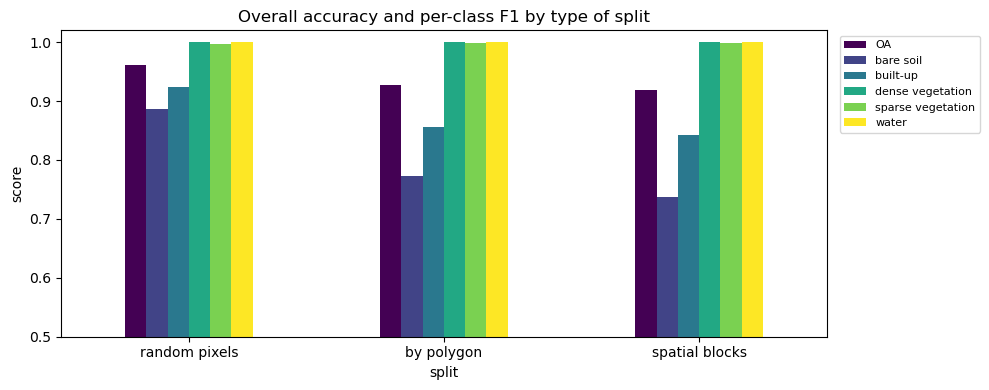

In [17]:
cv_results.plot(kind="bar", figsize=(10, 4), rot=0, colormap="viridis")
plt.ylim(0.5, 1.02); plt.ylabel("score"); plt.title("Overall accuracy and per-class F1 by type of split")
plt.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

**Question 4.** (a) Rank the three estimates and explain the differences. (b) Which classes are most affected, and why? (c) Which estimate would you report for a map of districts where no polygons were collected?

*Your answer:*

- **(a) Ranking of estimates:**
  1. **Random pixels:** Overall Accuracy (OA) $\approx$ **0.96** (highest, most optimistic).
  2. **By polygon:** OA $\approx$ **0.93** (intermediate).
  3. **Spatial blocks (5 km):** OA $\approx$ **0.92** (lowest, most realistic).
  *Explanation:* Random pixel splitting scatters neighbouring pixels of the same polygon across training and validation folds, causing severe spatial data leakage. Grouping by polygon prevents intra-polygon leakage. Spatial-block cross-validation further eliminates proximity advantages from nearby reference polygons.
- **(b) Most affected classes:** **Bare soil** ($F_1$ drops from ~0.89 to ~0.73) and **built-up** ($F_1$ drops from ~0.92 to ~0.84). Because bare ground and urban materials are spectrally very similar, the model heavily exploits spatial proximity when folds are random. Water and vegetation remain stable because their spectral signatures are inherently distinct.
- **(c) Estimate to report:** Report the **spatial-block CV** estimate (or leave-region-out CV), because it tests how well the model predicts in unsampled geographic areas without spatial autocorrelation leakage.